# Comparativa: Q-Learning, SARSA y Monte Carlo

Este notebook responde al ejercicio 4: una tabla con todos los algoritmos y los *baselines* en cada mercado, con su rendimiento y su tiempo de convergencia.

Cada algoritmo se hizo por separado (`q_learning.ipynb`, `taller_trader_sarsa.ipynb` y `monte_carlo.ipynb`). Al juntarlos vimos que Q-Learning y SARSA no se evaluaban sobre las mismas series de test, ni con las mismas métricas, ni con el mismo criterio de convergencia, así que sus tablas no se podían comparar directamente. Aquí lo volvemos a evaluar todo con el protocolo de `q_learning.ipynb` (el código está en `trader_rl.py`):

| | Protocolo común |
|---|---|
| Entrenamiento | 5 semillas × 3000 episodios, una serie nueva por episodio, con los hiperparámetros elegidos en el notebook de cada algoritmo |
| Validación | las mismas 30 series por mercado; curva de aprendizaje cada 100 episodios |
| Test | las mismas 100 series por mercado, que no se han usado para ajustar nada; se promedia sobre semillas y series |
| Rendimiento | log-retorno medio, retorno geométrico y mediano, % de series en que se gana a *buy & hold*, Sharpe, *drawdown*, operaciones |
| Convergencia | el mismo criterio para todos: primer episodio a partir del cual la curva de validación ya no se sale de una banda alrededor de su valor final |
| Coste | ms por episodio medidos uno detrás de otro en el mismo ordenador y sin validación, para que los tiempos se puedan comparar |

De dónde sale cada agente:

- **Q-Learning, Double Q-Learning y Q-Learning con estado ampliado:** son los agentes ya entrenados en `q_learning.ipynb` (`cache_qlearning/`); aquí solo se cargan.
- **SARSA:** los agentes de `taller_trader_sarsa.ipynb` no se guardaron, así que los volvemos a entrenar con sus mejores hiperparámetros y su mismo código (`AgenteSarsa`). Lo único que cambia son las series de validación.
- **Monte Carlo:** los agentes de `cache_montecarlo/`.
- **Dos experimentos de control,** explicados en la sección 5, para ver si las diferencias vienen del algoritmo o de los hiperparámetros.

## 1. Configuración y carga de agentes

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, dump, load

# QLearningAgent y Discretizer se importan con su nombre porque los agentes de cache_qlearning/ se guardaron
# desde la libreta y el pickle los busca en __main__
from trader_rl import (GENERATORS, SimpleTradingEnv, ExtendedTradingEnv, EXT_BINS, Discretizer, QLearningAgent,
                       train_q_learning, MonteCarloAgent, train_monte_carlo, AgenteSarsa, train_sarsa, SARSA_BEST_PARAMS,
                       val_sets, test_sets, evaluate, BASELINES, convergence_episode, summarize,
                       N_SEEDS, FINAL_EPISODES, EVAL_EVERY)

N_JOBS = -1
FIG_DIR = "figuras_comparativa"
CACHE_DIR = "cache_comparativa"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
RECOMPUTE = False

VAL, TEST = val_sets(), test_sets()
GENS = list(GENERATORS)

COLORS = {"Q-Learning": "#2a78d6", "SARSA": "#7c3aed", "Monte Carlo": "#c2410c",
          "SARSA (hiperparámetros de Q-Learning)": "#a78bfa", "Q-Learning (hiperparámetros de MC)": "#7fb2ea",
          "Double Q-Learning": "#008300", "Q-Learning (estado ampliado)": "#6250d6",
          "Buy & Hold": "#eb6834", "Aleatorio": "#1baf7a", "Siempre fuera": "#8a8984",
          "Momentum (regla)": "#eda100", "Contrarian (regla)": "#e87ba4"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})


def as_runs(raw):
    # (gen, seed, agent, disc, hist) -> {gen: [(policy_factory, hist), ...]}
    out = {g: [] for g in GENS}
    for g, sd, agent, disc, hist in raw:
        out[g].append((lambda a=agent, d=disc: a.greedy_policy(d), hist))
    return out


QL_HP = pd.read_csv("hiperparametros_qlearning.csv", index_col=0, encoding="utf-8-sig")
MC_HP = pd.read_csv("hiperparametros_montecarlo.csv", index_col=0, encoding="utf-8-sig")

RUNS = {
    "Q-Learning": as_runs(load("cache_qlearning/agentes_finales.joblib")),
    "Double Q-Learning": as_runs(load("cache_qlearning/agentes_double_q.joblib")),
    "Q-Learning (estado ampliado)": as_runs(load("cache_qlearning/agentes_estado_ampliado.joblib")),
    "Monte Carlo": as_runs(load("cache_montecarlo/agentes_finales.joblib")),
}
ENV_OF = {"Q-Learning (estado ampliado)": ExtendedTradingEnv}

### SARSA, reentrenado con el protocolo común

Usamos los hiperparámetros que salieron mejores en `taller_trader_sarsa.ipynb` (búsqueda aleatoria de 40 configuraciones y reevaluación de las 3 mejores), con su discretizador, su máscara de acciones válidas y su $\alpha$ decreciente. También entrenamos una variante de control con los hiperparámetros de Q-Learning ($\alpha$ fijo, $\gamma$, nº de intervalos y calendario de $\epsilon$).

In [2]:
def ql_params_for_sarsa(g):
    h = QL_HP.loc[g]
    return {"alpha": float(h.alpha), "alpha_final": None, "gamma": float(h.gamma), "n_bins": int(h.n_bins),
            "eps_final": float(h.eps_min), "eps_frac": float(h.decay_frac)}


SARSA_VARIANTS = {"SARSA": SARSA_BEST_PARAMS,
                  "SARSA (hiperparámetros de Q-Learning)": {g: ql_params_for_sarsa(g) for g in GENS}}


def sarsa_job(label, g, seed):
    agent, hist = train_sarsa(g, SARSA_VARIANTS[label][g], seed=seed, val_series=val_sets()[g])
    return label, g, seed, agent, hist


sarsa_path = f"{CACHE_DIR}/agentes_sarsa.joblib"
if RECOMPUTE or not os.path.exists(sarsa_path):
    t0 = time.perf_counter()
    dump(Parallel(n_jobs=N_JOBS)(delayed(sarsa_job)(lab, g, sd) for lab in SARSA_VARIANTS for g in GENS
                                 for sd in range(N_SEEDS)), sarsa_path)
    print(f"{2 * len(GENS) * N_SEEDS} entrenamientos de SARSA en {time.perf_counter() - t0:.0f} s")
for lab in SARSA_VARIANTS:
    RUNS[lab] = {g: [(lambda a=agent: a.politica, hist) for l, gg, sd, agent, hist in load(sarsa_path)
                     if l == lab and gg == g] for g in GENS}

pd.DataFrame({lab: {g: str(p) for g, p in v.items()} for lab, v in SARSA_VARIANTS.items()})

,SARSA,SARSA (hiperparámetros de Q-Learning)
Tendencia + ciclo,"{'alpha': 0.014, 'alpha_final': 0.0014, 'gamma...","{'alpha': 0.01, 'alpha_final': None, 'gamma': ..."
Browniano,"{'alpha': 0.0251, 'alpha_final': 0.00251, 'gam...","{'alpha': 0.01, 'alpha_final': None, 'gamma': ..."
Reversión a la media,"{'alpha': 0.007, 'alpha_final': 7e-05, 'gamma'...","{'alpha': 0.01, 'alpha_final': None, 'gamma': ..."
Regímenes,"{'alpha': 0.0152, 'alpha_final': 0.00152, 'gam...","{'alpha': 0.01, 'alpha_final': None, 'gamma': ..."


### Q-Learning con los hiperparámetros de Monte Carlo

La rejilla de Monte Carlo incluía valores de $\alpha$ más pequeños que la de Q-Learning, que empezaba en 0,01. Además, con $\gamma = 0$ (lo que eligió Monte Carlo) los dos algoritmos tienen exactamente el mismo objetivo: $G_t = R_{t+1}$. Para saber si la diferencia entre ellos es del algoritmo o de los hiperparámetros, entrenamos Q-Learning con los de Monte Carlo. En los mercados donde Monte Carlo eligió $\alpha = 1/N$, que Q-Learning no admite, ponemos $\alpha = 0.001$.

In [3]:
def mc_params_for_ql(g):
    h = MC_HP.loc[g]
    return {"n_bins": int(h.n_bins), "alpha": 0.001 if pd.isna(h.alpha) else float(h.alpha), "gamma": float(h.gamma),
            "eps_min": float(h.eps_min), "decay_frac": float(h.decay_frac)}


def ql_mc_job(g, seed):
    hp = mc_params_for_ql(g)
    disc = Discretizer(g, {0: hp.pop("n_bins")})
    agent, hist = train_q_learning(g, disc, n_episodes=FINAL_EPISODES, seed=seed, val_series=val_sets()[g],
                                   eval_every=EVAL_EVERY, **hp)
    return g, seed, agent, disc, hist


qlmc_path = f"{CACHE_DIR}/agentes_qlearning_hp_mc.joblib"
if RECOMPUTE or not os.path.exists(qlmc_path):
    t0 = time.perf_counter()
    dump(Parallel(n_jobs=N_JOBS)(delayed(ql_mc_job)(g, sd) for g in GENS for sd in range(N_SEEDS)), qlmc_path)
    print(f"{len(GENS) * N_SEEDS} entrenamientos en {time.perf_counter() - t0:.0f} s")
RUNS["Q-Learning (hiperparámetros de MC)"] = as_runs(load(qlmc_path))
pd.DataFrame({g: mc_params_for_ql(g) for g in GENS}).T

,n_bins,alpha,gamma,eps_min,decay_frac
Tendencia + ciclo,20.0,0.001,0.0,0.01,0.6
Browniano,20.0,0.001,0.0,0.10,0.6
Reversión a la media,20.0,0.001,0.0,0.05,0.3
Regímenes,20.0,0.001,0.9,0.10,0.3


## 2. Coste por episodio

Los tiempos que aparecen en cada notebook no se pueden comparar entre sí: se midieron con distinto número de procesos en paralelo y algunos incluyen las evaluaciones en validación. Aquí entrenamos cada algoritmo 100 episodios, uno detrás de otro, en el mismo ordenador y sin validar, y medimos cuánto tarda un episodio. Repetimos cada medida 3 veces y nos quedamos con la más rápida, para que no influya que el sistema haga otra cosa en ese momento. El tiempo hasta convergencia es ese coste por el número de episodios que tarda en converger.

In [4]:
N_BENCH = 100


def bench_once(label, g):
    if label in ("Q-Learning", "Double Q-Learning"):
        hp = QL_HP.loc[g].to_dict()
        disc = Discretizer(g, {0: int(hp.pop("n_bins"))})
        t0 = time.perf_counter()
        train_q_learning(g, disc, n_episodes=N_BENCH, double=label == "Double Q-Learning", **hp)
    elif label == "Q-Learning (hiperparámetros de MC)":
        hp = mc_params_for_ql(g)
        disc = Discretizer(g, {0: hp.pop("n_bins")})
        t0 = time.perf_counter()
        train_q_learning(g, disc, n_episodes=N_BENCH, **hp)
    elif label == "Q-Learning (estado ampliado)":
        disc = Discretizer(g, EXT_BINS, env_cls=ExtendedTradingEnv)
        t0 = time.perf_counter()
        train_q_learning(g, disc, n_episodes=N_BENCH, env_cls=ExtendedTradingEnv,
                         alpha=0.01, gamma=0.9, eps_min=0.05, decay_frac=0.6)
    elif label == "Monte Carlo":
        hp = MC_HP.loc[g].to_dict()
        disc = Discretizer(g, {0: int(hp.pop("n_bins"))})
        hp["alpha"] = None if pd.isna(hp["alpha"]) else float(hp["alpha"])
        hp["first_visit"] = str(hp["first_visit"]) == "True"
        t0 = time.perf_counter()
        train_monte_carlo(g, disc, n_episodes=N_BENCH, **hp)
    else:
        t0 = time.perf_counter()
        train_sarsa(g, SARSA_VARIANTS[label][g], n_episodes=N_BENCH)
    return 1000 * (time.perf_counter() - t0) / N_BENCH   # incluye el ajuste del discretizador de SARSA (despreciable)


def bench(label, g, repeats=3):
    return min(bench_once(label, g) for _ in range(repeats))


bench_path = f"{CACHE_DIR}/coste_por_episodio.csv"
if RECOMPUTE or not os.path.exists(bench_path):
    rows = [{"Agente": lab, "Generador": g, "ms/episodio": bench(lab, g)} for lab in RUNS for g in GENS]
    pd.DataFrame(rows).to_csv(bench_path, index=False)
cost = pd.read_csv(bench_path).set_index(["Generador", "Agente"])["ms/episodio"]
cost.unstack().loc[GENS].round(1)

Agente,Double Q-Learning,Monte Carlo,Q-Learning,Q-Learning (estado ampliado),Q-Learning (hiperparámetros de MC),SARSA,SARSA (hiperparámetros de Q-Learning)
Generador,,,,,,,
Tendencia + ciclo,8.1,9.6,8.0,18.8,9.8,8.0,8.2
Browniano,10.4,9.2,10.4,21.7,10.6,7.7,8.0
Reversión a la media,8.5,10.8,8.4,21.2,10.8,8.8,8.6
Regímenes,8.3,8.9,8.3,23.3,9.1,9.1,8.6


## 3. Test y tabla comparativa

In [5]:
test_results, rows = {}, []
for g in GENS:
    for name, factory in BASELINES.items():
        res = evaluate(TEST[g], factory)
        test_results[(g, name)] = res
        rows.append(summarize(res, name, g))
    for label, runs in RUNS.items():
        env_cls = ENV_OF.get(label, SimpleTradingEnv)
        per_seed = [evaluate(TEST[g], lambda i, f=f: f(), env_cls) for f, _ in runs[g]]
        res = pd.concat(per_seed, ignore_index=True)
        test_results[(g, label)] = res
        convs = [convergence_episode(h["val_ep"], h["val_logret"]) for _, h in runs[g]]
        ms = cost.loc[(g, label)]
        rows.append(summarize(res, label, g, {
            "Std log-ret. entre semillas": np.std([r["log_ret"].mean() for r in per_seed]),
            "Episodios hasta convergencia": np.median(convs),
            "ms/episodio": ms,
            "Tiempo hasta convergencia (s)": np.median(convs) * ms / 1000}))

for r in rows:
    bh = test_results[(r["Generador"], "Buy & Hold")]["log_ret"].values
    mine = test_results[(r["Generador"], r["Agente"])]["log_ret"].values
    r["% series > B&H"] = 100 * np.mean(mine > np.tile(bh, len(mine) // len(bh)))

table = pd.DataFrame(rows).set_index(["Generador", "Agente"])
ALGOS = ["Q-Learning", "SARSA", "Monte Carlo"]
BASE = ["Buy & Hold", "Aleatorio", "Siempre fuera", "Momentum (regla)", "Contrarian (regla)"]
CONTROL = ["SARSA (hiperparámetros de Q-Learning)", "Q-Learning (hiperparámetros de MC)"]
EXTRA = CONTROL + ["Double Q-Learning", "Q-Learning (estado ampliado)"]
perf_cols = ["Log-ret. medio", "Ret. geométrico (%)", "Ret. mediano (%)", "% series > B&H", "Sharpe",
             "Max DD (%)", "Operaciones", "% tiempo invertido"]
conv_cols = ["Std log-ret. entre semillas", "Episodios hasta convergencia", "ms/episodio", "Tiempo hasta convergencia (s)"]
table = table.loc[[(g, a) for g in GENS for a in ALGOS + BASE + EXTRA], perf_cols + conv_cols].astype(float)
table.to_csv("tabla_comparativa.csv", encoding="utf-8-sig", float_format="%.4f")

### Tabla principal: los tres algoritmos y los *baselines*

En los algoritmos, las métricas son la media de 5 semillas × 100 series de test. La columna de desviación entre semillas mide cuánto cambia el log-retorno medio de una semilla a otra, y los episodios hasta convergencia son la mediana de las 5 semillas.

In [6]:
def fmt(df):
    f = {"Log-ret. medio": "{:.3f}", "Ret. geométrico (%)": "{:,.1f}", "Ret. mediano (%)": "{:,.1f}",
         "% series > B&H": "{:.0f}", "Sharpe": "{:.2f}", "Max DD (%)": "{:.1f}", "Operaciones": "{:.1f}",
         "% tiempo invertido": "{:.1f}", "Std log-ret. entre semillas": "{:.3f}",
         "Episodios hasta convergencia": "{:.0f}", "ms/episodio": "{:.1f}", "Tiempo hasta convergencia (s)": "{:.1f}"}
    return df.style.format(f, na_rep="—")


main = table.loc[[(g, a) for g in GENS for a in ALGOS + BASE]]
fmt(main)

### Experimentos de control: ¿algoritmo o hiperparámetros?

In [7]:
fmt(table.loc[[(g, a) for g in GENS for a in ALGOS + CONTROL]])

### Extensiones de Q-Learning

In [8]:
fmt(table.loc[[(g, a) for g in GENS for a in ["Q-Learning", "Double Q-Learning", "Q-Learning (estado ampliado)"]]])

### Resumen para el informe

Log-retorno medio en test (entre paréntesis, la desviación entre semillas) y episodios hasta convergencia.

In [9]:
summary = pd.DataFrame({
    a: [f"{table.loc[(g, a), 'Log-ret. medio']:+.3f}" +
        (f" (±{table.loc[(g, a), 'Std log-ret. entre semillas']:.3f})" if a in ALGOS + EXTRA else "")
        for g in GENS]
    for a in ALGOS + ["Buy & Hold", "Aleatorio"]}, index=GENS)
conv = pd.DataFrame({a: [f"{table.loc[(g, a), 'Episodios hasta convergencia']:.0f} ep. / "
                         f"{table.loc[(g, a), 'Tiempo hasta convergencia (s)']:.1f} s" for g in GENS] for a in ALGOS},
                    index=GENS)
display(summary)
conv

,Q-Learning,SARSA,Monte Carlo,Buy & Hold,Aleatorio
Tendencia + ciclo,+6.338 (±0.102),+6.316 (±0.234),+6.522 (±0.039),+3.316,+1.558
Browniano,+0.000 (±0.000),+0.000 (±0.000),-0.012 (±0.025),-0.062,-0.187
Reversión a la media,+0.155 (±0.042),+0.203 (±0.025),+0.238 (±0.015),-0.005,-0.169
Regímenes,+0.040 (±0.022),+0.000 (±0.000),+0.031 (±0.011),-0.128,-0.220


,Q-Learning,SARSA,Monte Carlo
Tendencia + ciclo,300 ep. / 2.4 s,500 ep. / 4.0 s,500 ep. / 4.8 s
Browniano,400 ep. / 4.2 s,1700 ep. / 13.0 s,700 ep. / 6.5 s
Reversión a la media,2200 ep. / 18.6 s,1600 ep. / 14.1 s,1600 ep. / 17.3 s
Regímenes,2000 ep. / 16.6 s,600 ep. / 5.5 s,1300 ep. / 11.5 s


## 4. Figuras

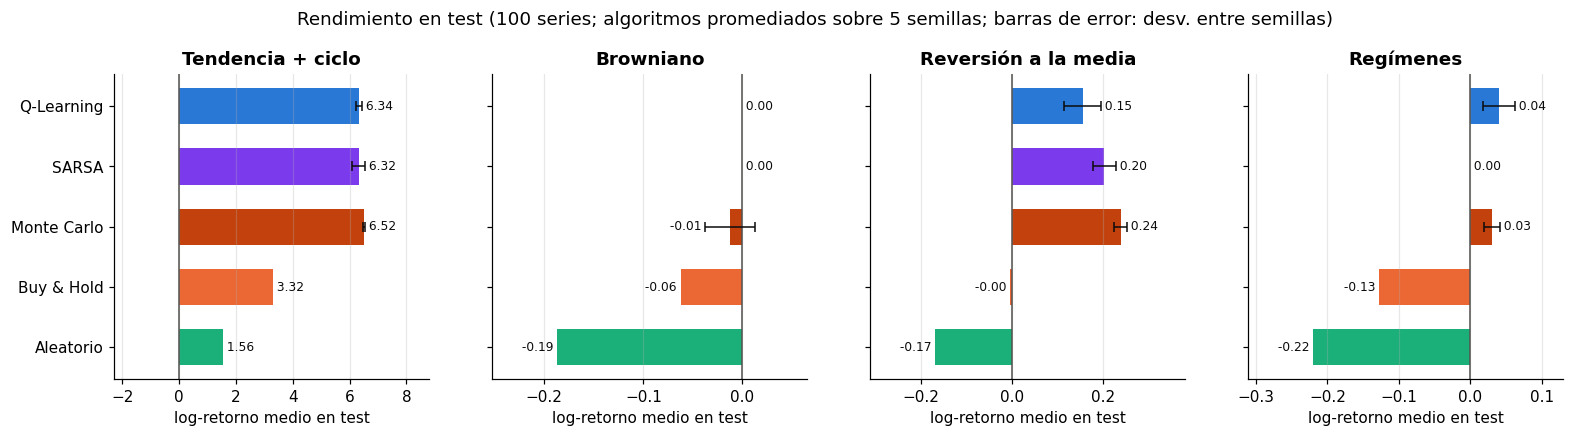

In [10]:
show = ALGOS + ["Buy & Hold", "Aleatorio"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, g in zip(axes, GENS):
    vals = [table.loc[(g, a), "Log-ret. medio"] for a in show]
    errs = [table.loc[(g, a), "Std log-ret. entre semillas"] if a in ALGOS else 0 for a in show]
    ax.barh(range(len(show)), vals, color=[COLORS[a] for a in show], height=0.6)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(show)), show if g == GENS[0] else [""] * len(show))
    ax.invert_yaxis()
    ax.set_title(g)
    ax.set_xlabel("log-retorno medio en test")
    for k, (v, e) in enumerate(zip(vals, errs)):
        if e > 0:
            ax.errorbar(v, k, xerr=e, fmt="none", ecolor="#0b0b0b", capsize=3, lw=1)
        x = v + e if v >= 0 else v - e    # la etiqueta va después de la barra de error
        ax.text(x, k, f" {v:.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#0b0b0b")
    lo, hi = min(0, min(vals)), max(0, max(vals))
    pad = 0.35 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.grid(axis="y", visible=False)
fig.suptitle("Rendimiento en test (100 series; algoritmos promediados sobre 5 semillas; barras de error: desv. entre semillas)", y=1.04)
plt.savefig(f"{FIG_DIR}/rendimiento_test.png", bbox_inches="tight")
plt.show()

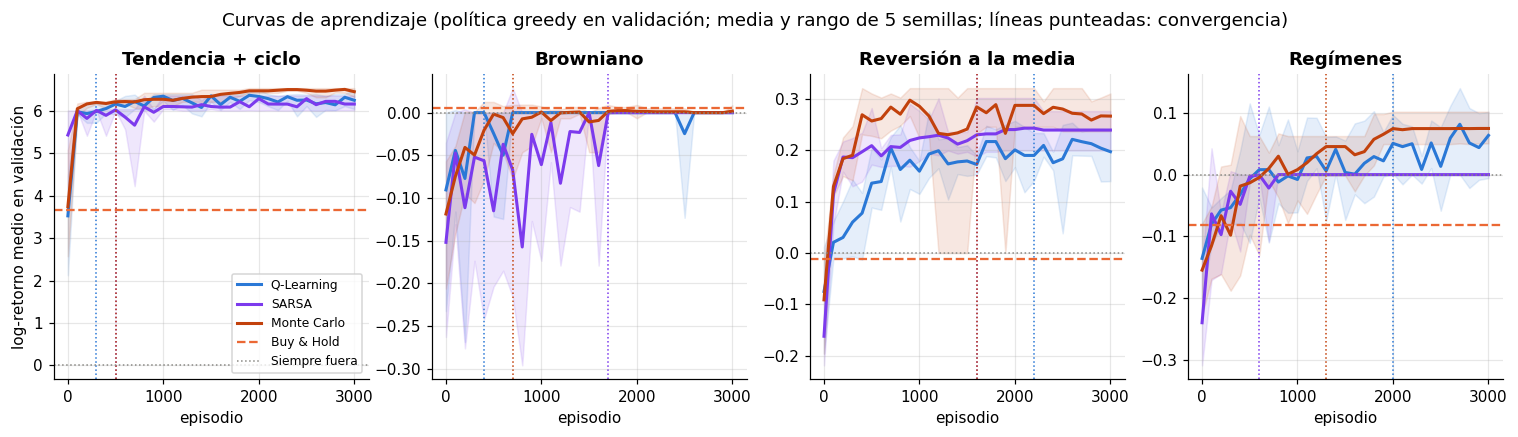

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, g in zip(axes, GENS):
    for a in ALGOS:
        hs = [h for _, h in RUNS[a][g]]
        ep = hs[0]["val_ep"]
        v = np.array([h["val_logret"] for h in hs])
        ax.plot(ep, v.mean(0), color=COLORS[a], lw=2, label=a)
        ax.fill_between(ep, v.min(0), v.max(0), color=COLORS[a], alpha=0.12)
        c = table.loc[(g, a), "Episodios hasta convergencia"]
        ax.axvline(c, color=COLORS[a], lw=1, ls=":")
    bh = evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean()
    ax.axhline(bh, color=COLORS["Buy & Hold"], ls="--", lw=1.5, label="Buy & Hold")
    ax.axhline(0, color=COLORS["Siempre fuera"], ls=":", lw=1, label="Siempre fuera")
    ax.set_title(g)
    ax.set_xlabel("episodio")
axes[0].set_ylabel("log-retorno medio en validación")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Curvas de aprendizaje (política greedy en validación; media y rango de 5 semillas; líneas punteadas: convergencia)", y=1.04)
plt.savefig(f"{FIG_DIR}/curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

## 5. Análisis

### Rendimiento

En general los tres algoritmos ganan a *buy & hold* y al agente aleatorio en los cuatro mercados. La excepción es el browniano, donde lo mejor que se puede hacer es no operar: Q-Learning y SARSA lo consiguen (0 %) y Monte Carlo pierde un 1,2 %.

- **Tendencia + ciclo.** Los tres aprenden *momentum* con histéresis. Sacan un log-retorno de entre 6,32 y 6,52, frente a 3,32 de *buy & hold* y 6,11 de la regla fija de *momentum*. Ganan a *buy & hold* en el 96–97 % de las series y operan entre 40 y 58 veces por episodio, cuando la regla opera 93. Las diferencias entre algoritmos son del mismo tamaño que las diferencias entre semillas (0,04–0,23), así que aquí no hay un ganador claro.
- **Browniano.** Q-Learning y SARSA no operan nunca. Monte Carlo casi nunca compra (0,2 operaciones por episodio), pero cuando compra ya no vende y pasa un 19 % del tiempo dentro. Sus hiperparámetros para este mercado (*first-visit* y $\alpha = 1/N$) se eligieron por un +0,014 en validación que era puro ruido.
- **Reversión a la media.** Monte Carlo gana un 26,9 %, SARSA un 22,5 % y Q-Learning un 16,7 %. Todos quedan muy por encima de *buy & hold* (−0,5 %) y de la regla *contrarian* (+7,1 %), le ganan a *buy & hold* en el 80–90 % de las series y con menos *drawdown*.
- **Regímenes.** Q-Learning gana un 4 % y Monte Carlo un 3,1 %, cuando *buy & hold* pierde un 12 %. SARSA aprende a no operar.

### ¿Algoritmo o hiperparámetros?

Como cada algoritmo se ajustó con una búsqueda distinta, las diferencias de la tabla principal mezclan dos cosas. Los experimentos de control sirven para separarlas.

- **Q-Learning con los hiperparámetros de Monte Carlo saca prácticamente lo mismo que Monte Carlo:** 6,517 frente a 6,522 en tendencia y 0,222 frente a 0,238 en reversión. La ventaja de Monte Carlo no viene del algoritmo, sino de usar $\alpha = 0.001$, un valor que no estaba en la rejilla de Q-Learning (y cuyo mejor $\alpha$ había salido justo en el borde, 0,01). Con estos hiperparámetros Q-Learning llega incluso a un +8 % en regímenes, el mejor resultado de los algoritmos base. El precio de un $\alpha$ tan pequeño es que tarda más en converger (800 episodios en vez de 300 en tendencia + ciclo).
- **SARSA con los hiperparámetros de Q-Learning sigue sin operar en regímenes** (0 frente a 0,040 de Q-Learning) y rinde menos en reversión (0,099 frente a 0,155). Aquí la diferencia sí es del algoritmo. SARSA es on-policy y aprende cuánto vale la política $\epsilon$-greedy que está siguiendo ($\epsilon_{min}$ entre 0,05 y 0,1). Como explorar en este entorno significa comprar y vender al azar pagando comisión, cuando la señal es débil le sale más a cuenta no hacer nada. Q-Learning es off-policy, aprende el valor de la política *greedy* y sí detecta esa pequeña ventaja. Es lo mismo que pasaba en el *Cliff Walking* de clase, donde SARSA elegía el camino seguro. La diferencia es que aquí no hay acantilado (explorar solo cuesta una comisión) y esa prudencia simplemente hace perder rentabilidad.

### Convergencia y coste

- **La velocidad depende más del mercado que del algoritmo.** En tendencia + ciclo los tres convergen en 300–500 episodios (2–5 s); en reversión y regímenes hacen falta 1300–2200 (11–19 s). La excepción es SARSA en regímenes, que converge en 600 episodios porque converge a no operar. Cuanto más débil es la señal comparada con el ruido, más episodios hacen falta para que la diferencia entre acciones se note en $Q$.
- **Monte Carlo no converge más despacio que TD,** aunque su objetivo sea más ruidoso, porque eligió $\gamma = 0$ (o 0,9 en regímenes). Con ese horizonte su objetivo es casi igual de ruidoso que el de TD (sección 3 de `monte_carlo.ipynb`). Con $\gamma = 0.99$, que es lo que necesitó Q-Learning en reversión y regímenes, Monte Carlo va bastante peor.
- **En el browniano, SARSA tarda 1700 episodios en dejar de operar,** con caídas en la curva hasta entonces; Q-Learning lo consigue en 400.
- **Cada episodio cuesta unos 8–11 ms en los tres algoritmos.** Casi todo el tiempo se va en simular el entorno, así que el tiempo hasta converger es prácticamente proporcional al número de episodios. Solo el estado ampliado lo duplica (19–23 ms), porque tiene que calcular las variables extra.

### Extensiones

- El estado ampliado sigue siendo la mayor mejora: +37 % en reversión y +17 % en regímenes, más que cualquier cambio de algoritmo o de hiperparámetros.
- Double Q-Learning no se distingue de Q-Learning, teniendo en cuenta la variación entre semillas.

### En resumen

En este problema importa más qué información tiene el estado y cómo se eligen $\alpha$ y $\gamma$ que el algoritmo tabular concreto. La única diferencia de algoritmo que se mantiene en todas las pruebas es la de on-policy frente a off-policy: SARSA es más conservador y deja pasar señales débiles que Q-Learning sí aprovecha. Monte Carlo funciona bien, pero porque esquiva su punto débil, la varianza del retorno, eligiendo un horizonte de un solo paso.